# Random Forest: baseline y mejora (US-08)

**Issue:** #20. **Modelo de:** Rita.

Este notebook **no entrena para elegir nada**: lee las métricas ya registradas por `src/train_random_forest.py` en `results/random_forest.csv` y las explica con tablas y figuras. Solo vuelve a ajustar el modelo elegido (misma semilla, mismos datos) para dibujar la matriz de confusión y la importancia de las variables.

**Cómo se generaron los resultados** (desde la raíz del repo):

```
python -m src.train_random_forest --stage baseline
python -m src.train_random_forest --stage tune
```

**Reglas que se siguen**
- Datos: `train_70` para entrenar y `val_15` para evaluar. `test_15` no se abre (D-006, D-013).
- Preprocesado: Pipeline común con la imputación de D-011 y el encoding de D-014, ajustado solo con train.
- Métrica principal: macro-F1 en validación. Sobreajuste: accuracy(train) − accuracy(val) < 5 puntos (D-010).
- Ajuste de hiperparámetros: validación cruzada de 5 particiones sobre `train_70`; `val_15` no se usa para elegir entre configuraciones (D-010, punto 6).

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

from src.config import FEATURE_COLUMNS
from src.preprocessing import make_features_target
from src.train_random_forest import CLASSES, build_model, load_partitions

RESULTS_PATH = "results/random_forest.csv"
FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"
BLUE, GRAY, ORANGE = "#2a78d6", "#c3c2b7", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
pd.set_option("display.max_colwidth", 90)

## 1. Resultados registrados

In [2]:
results = pd.read_csv(RESULTS_PATH)
print("Filas:", len(results), "| ejecuciones:", results["run_timestamp_utc"].nunique(),
      "| semilla:", results["seed"].unique().tolist())
results["partition"].value_counts().to_frame("filas")

Filas: 64 | ejecuciones: 2 | semilla: [42]


,filas
partition,
cv5fold,60
train_70,2
val_15,2


## 2. Baseline frente a modelo ajustado

El **baseline** usa los valores por defecto de scikit-learn (100 árboles sin límite de profundidad). El **ajustado** es la configuración elegida en la fase de mejora. La columna `gap` es accuracy(train) − accuracy(val) en puntos porcentuales: tiene que ser menor que 5.

In [3]:
final = results[results["partition"].isin(["train_70", "val_15"])].copy()
final["modelo"] = final["config"].str.split(" ").str[0]

summary = final.pivot(index="modelo", columns="partition", values=["accuracy", "macro_f1"])
summary.columns = [f"{m}_{p}" for m, p in summary.columns]
summary["gap_accuracy_puntos"] = (summary["accuracy_train_70"] - summary["accuracy_val_15"]) * 100
summary["gap_relativo_%"] = summary["gap_accuracy_puntos"] / summary["accuracy_train_70"]
summary["gap_macro_f1"] = summary["macro_f1_train_70"] - summary["macro_f1_val_15"]
summary["cumple_<5_puntos"] = summary["gap_accuracy_puntos"] < 5
summary.loc[["baseline", "tuned"]].round(4).T

modelo,baseline,tuned
accuracy_train_70,0.9683,0.5628
accuracy_val_15,0.4983,0.5421
macro_f1_train_70,0.9675,0.5442
macro_f1_val_15,0.4849,0.5197
gap_accuracy_puntos,47.0,2.07
gap_relativo_%,48.5387,3.678
gap_macro_f1,0.4826,0.0245
cumple_<5_puntos,False,True


In [4]:
tuned_config = final.loc[final["modelo"] == "tuned", "config"].iloc[0]
tuned_params = json.loads(tuned_config.split(" ", 1)[1])
print("Configuración elegida:", tuned_params)

Configuración elegida: {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 300}


### F1 por clase en validación

Muestra qué segmentos reconoce bien el modelo y cuáles confunde.

In [5]:
per_class = (final[final["partition"] == "val_15"]
             .set_index("modelo")[[f"f1_{c}" for c in CLASSES]].loc[["baseline", "tuned"]])
per_class.columns = list(CLASSES)
per_class.round(3)

,A,B,C,D
modelo,,,,
baseline,0.384,0.360,0.536,0.660
tuned,0.448,0.359,0.556,0.715


## 3. Fase de mejora: 60 configuraciones con validación cruzada

Cada punto es una configuración. En horizontal, cuánto sobreajusta (accuracy de train menos accuracy de validación cruzada); en vertical, su macro-F1 en validación cruzada. Solo son admisibles las que quedan a la izquierda de la línea de 5 puntos; entre ellas se elige la de mayor macro-F1.

In [6]:
cv = results[results["partition"] == "cv5fold"].copy()
cv["params"] = cv["config"].str.split(" ", n=1).str[1].map(json.loads)
cv = pd.concat([cv.reset_index(drop=True), pd.json_normalize(cv["params"].tolist())], axis=1)
cv["gap_puntos"] = cv["notes"].str.extract(r"train - CV gap ([\d.]+)").astype(float)
cv["sd_macro_f1"] = cv["notes"].str.extract(r"sd macro-F1 ([\d.]+)").astype(float)
cv["admisible"] = cv["gap_puntos"] < 5
cv["max_depth"] = cv["max_depth"].map(lambda d: "sin límite" if pd.isna(d) else str(int(d)))

print("Configuraciones admisibles (gap < 5 puntos):", int(cv["admisible"].sum()), "de", len(cv))
cols = ["max_depth", "min_samples_leaf", "max_features", "macro_f1", "sd_macro_f1", "accuracy", "gap_puntos"]
cv[cv["admisible"]].sort_values("macro_f1", ascending=False)[cols].head(8)

Configuraciones admisibles (gap < 5 puntos): 35 de 60


,max_depth,min_samples_leaf,max_features,macro_f1,sd_macro_f1,accuracy,gap_puntos
46,12,20,sqrt,0.5084,0.0101,0.5275,3.75
27,8,20,0.5,0.5080,0.0083,0.5265,3.83
15,6,10,0.5,0.5078,0.0077,0.5226,2.89
11,6,1,0.5,0.5075,0.0071,0.5222,3.85
36,10,20,sqrt,0.5075,0.0068,0.5265,3.79
37,10,20,0.5,0.5070,0.0059,0.5251,4.91
56,sin límite,20,sqrt,0.5069,0.0099,0.5259,3.92
59,sin límite,40,0.5,0.5067,0.0066,0.5249,2.58


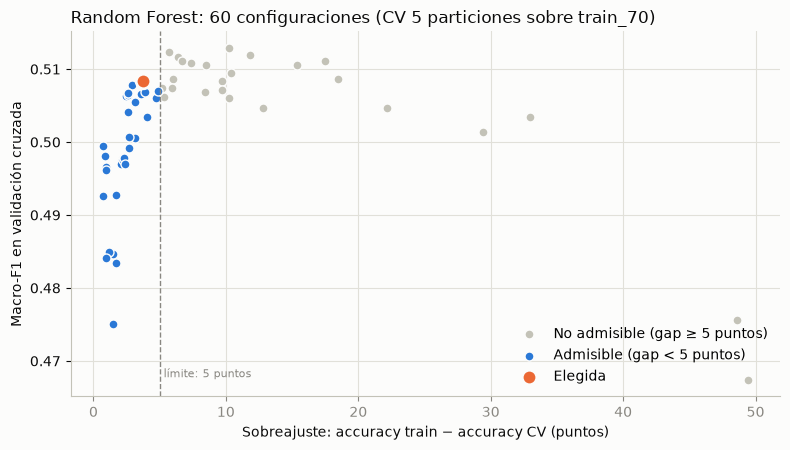

In [7]:
is_selected = cv["params"].map(lambda p: p == tuned_params)
fig, ax = plt.subplots(figsize=(8, 4.6))
for ok, color, label in [(False, GRAY, "No admisible (gap ≥ 5 puntos)"), (True, BLUE, "Admisible (gap < 5 puntos)")]:
    sub = cv[(cv["admisible"] == ok) & ~is_selected]
    ax.scatter(sub["gap_puntos"], sub["macro_f1"], s=42, color=color, edgecolor=SURFACE, linewidth=1, label=label)
sel = cv[is_selected].iloc[0]
ax.scatter(sel["gap_puntos"], sel["macro_f1"], s=110, color=ORANGE, edgecolor=SURFACE, linewidth=2, label="Elegida", zorder=3)
ax.axvline(5, color=MUTED, linewidth=1, linestyle="--")
ax.text(5.3, cv["macro_f1"].min(), "límite: 5 puntos", color=MUTED, fontsize=8, va="bottom")
ax.set_xlabel("Sobreajuste: accuracy train − accuracy CV (puntos)")
ax.set_ylabel("Macro-F1 en validación cruzada")
ax.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Random Forest: 60 configuraciones (CV 5 particiones sobre train_70)", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "rf_tuning_cv.png"), dpi=120, facecolor=SURFACE)
plt.show()

### ¿Qué hiperparámetro controla el sobreajuste?

Media del sobreajuste (puntos) según profundidad máxima y mínimo de muestras por hoja. Cuanto más arriba y a la izquierda (árboles profundos con hojas pequeñas), más memoriza el modelo.

In [8]:
depth_order = ["4", "6", "8", "10", "12", "sin límite"]
gap_table = cv.pivot_table(index="max_depth", columns="min_samples_leaf", values="gap_puntos", aggfunc="mean").loc[depth_order]
gap_table.round(1)

min_samples_leaf,1,5,10,20,40
max_depth,,,,,
4,1.2,1.2,1.1,1.0,1.1
6,4.0,3.4,2.8,2.3,2.2
8,10.0,6.7,5.3,3.5,2.3
10,20.3,10.6,7.1,4.4,2.4
12,31.2,12.8,8.0,4.5,2.5
sin límite,49.0,14.7,8.5,4.6,2.5


In [9]:
f1_table = cv.pivot_table(index="max_depth", columns="min_samples_leaf", values="macro_f1", aggfunc="mean").loc[depth_order]
f1_table.round(3)

min_samples_leaf,1,5,10,20,40
max_depth,,,,,
4,0.491,0.491,0.491,0.490,0.484
6,0.505,0.504,0.504,0.502,0.496
8,0.509,0.510,0.507,0.507,0.501
10,0.507,0.508,0.510,0.507,0.502
12,0.502,0.512,0.509,0.508,0.502
sin límite,0.472,0.512,0.509,0.507,0.502


## 4. Modelo elegido: en qué se equivoca

Se vuelve a ajustar la configuración elegida sobre `train_70` (misma semilla) y se comprueba que reproduce las métricas registradas antes de dibujar nada.

In [10]:
frames = load_partitions()
X_train, y_train = make_features_target(frames["train_70"])
X_val, y_val = make_features_target(frames["val_15"])
model = build_model(**tuned_params).fit(X_train, y_train)
pred_val = model.predict(X_val)

recorded = final[(final["modelo"] == "tuned") & (final["partition"] == "val_15")]["accuracy"].iloc[0]
refit = (pred_val == y_val).mean()
assert abs(refit - recorded) < 1e-4, (refit, recorded)
print(f"Accuracy en val_15: {refit:.4f} (coincide con la registrada: {recorded:.4f})")

train_70: 5647 rows, SHA-256 (LF) 58da50146ebd... OK
val_15: 1210 rows, SHA-256 (LF) f7243496ce9a... OK
No ID overlap between train_70 and val_15.


Accuracy en val_15: 0.5421 (coincide con la registrada: 0.5421)


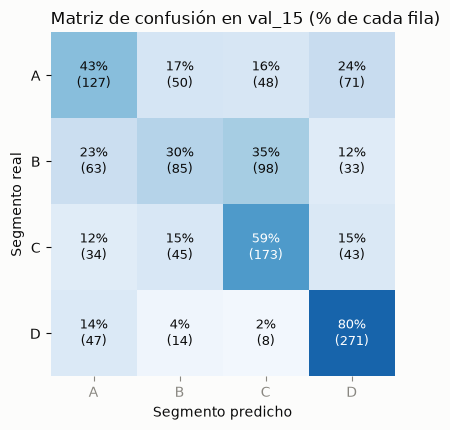

,pred A,pred B,pred C,pred D
real A,42.9,16.9,16.2,24.0
real B,22.6,30.5,35.1,11.8
real C,11.5,15.3,58.6,14.6
real D,13.8,4.1,2.4,79.7


In [11]:
cm = confusion_matrix(y_val, pred_val, labels=list(CLASSES))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm_pct[i, j]:.0f}%\n({cm[i, j]})", ha="center", va="center", fontsize=9,
                color="#ffffff" if cm_pct[i, j] > 50 else INK)
ax.set_xticks(range(4), CLASSES); ax.set_yticks(range(4), CLASSES)
ax.set_xlabel("Segmento predicho"); ax.set_ylabel("Segmento real")
ax.spines[:].set_visible(False)
ax.set_title("Matriz de confusión en val_15 (% de cada fila)", loc="left", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "rf_confusion_matrix_val.png"), dpi=120, facecolor=SURFACE)
plt.show()

pd.DataFrame(cm_pct, index=[f"real {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES]).round(1)

### Importancia de las variables

La importancia de un Random Forest mide cuánto reduce cada variable la impureza de los árboles. Las columnas one-hot se suman por variable original para poder compararlas. Es una medida **del modelo**, no una prueba de causa.

In [12]:
names = model.named_steps["preprocessing"].get_feature_names_out()
importances = model.named_steps["model"].feature_importances_


def source_variable(name):
    if name.startswith("missingindicator_"):
        return name.replace("missingindicator_", "") + " (indicador de nulo)"
    return next(col for col in sorted(FEATURE_COLUMNS, key=len, reverse=True) if name.startswith(col))


by_var = (pd.Series(importances, index=names).groupby(source_variable).sum().sort_values(ascending=False) * 100)
print("Columnas tras el preprocesado:", len(names))
by_var.round(1).to_frame("importancia_%")

Columnas tras el preprocesado: 29


,importancia_%
Profession,30.1
Age,23.5
Spending_Score,17.9
Graduated,7.7
Ever_Married,7.0
Family_Size,4.9
Var_1,3.6
Gender,2.5
Work_Experience,2.1
Work_Experience (indicador de nulo),0.4


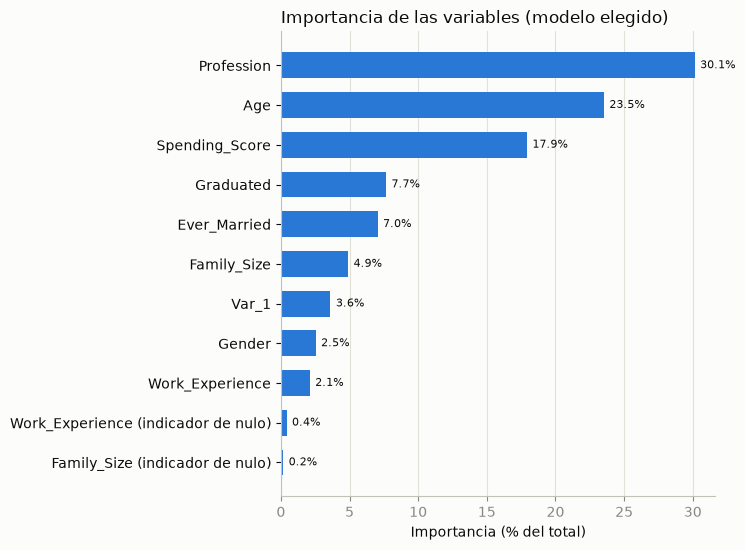

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 0.4 * len(by_var) + 1.2))
ax.barh(by_var.index[::-1], by_var.values[::-1], color=BLUE, height=0.65)
for y, v in enumerate(by_var.values[::-1]):
    ax.text(v + 0.4, y, f"{v:.1f}%", va="center", fontsize=8, color=INK)
ax.set_xlabel("Importancia (% del total)")
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Importancia de las variables (modelo elegido)", loc="left", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "rf_feature_importance.png"), dpi=120, facecolor=SURFACE)
plt.show()

## 5. Conclusiones

Todas las cifras salen de `results/random_forest.csv` y de las tablas de este notebook.

**Baseline**
- Con los valores por defecto, el Random Forest memoriza los datos de entrenamiento: accuracy de 96,8 % en train y 49,8 % en validación. La diferencia es de **47,0 puntos**, muy lejos del límite de 5. No cumple el criterio de D-010.
- Macro-F1 en validación: 0,485.

**Modelo ajustado**
- Configuración elegida: 300 árboles, `max_depth=12`, `min_samples_leaf=20`, `max_features="sqrt"`, semilla 42.
- Accuracy de 56,3 % en train y **54,2 % en validación**: diferencia de **2,07 puntos** (3,7 % en relativo). **Cumple** el límite de sobreajuste.
- Macro-F1 en validación: **0,520**, frente a 0,485 del baseline. Mejora el baseline en las dos métricas y, además, deja de sobreajustar.
- La diferencia se calcula aquí con las métricas guardadas con 4 decimales; el script, con todos los decimales, da 2,06.

**Qué redujo el sobreajuste**
- Sobre todo `min_samples_leaf`: obliga a que cada hoja agrupe al menos 20 clientes, así el árbol no puede aprenderse casos sueltos. Sin límite de profundidad, la diferencia baja de 49,0 puntos (hojas de 1) a 4,6 (hojas de 20).
- Limitar mucho la profundidad también lo corta (con `max_depth=4` la diferencia es de 1 punto), pero el modelo se queda corto: macro-F1 de 0,49 frente a 0,51.

**El modelo ha llegado a su techo con estas variables**
- De las 60 configuraciones, 35 cumplen el límite en validación cruzada. Las mejores están empatadas: macro-F1 entre 0,507 y 0,508, con una desviación entre particiones de alrededor de 0,01. Elegir una u otra no cambia el resultado.
- Las configuraciones con más macro-F1 (hasta 0,513) no son admisibles porque sobreajustan, y la ganancia es mínima.
- Es coherente con D-009: hay clientes con perfil idéntico en segmentos distintos, y eso limita lo que cualquier modelo puede acertar.

**En qué se equivoca**
- **D** es el segmento que mejor reconoce: acierta el 80 % (F1 0,715).
- **C**: acierta el 59 % (F1 0,556). **A**: acierta el 43 % (F1 0,448).
- **B** es el punto débil: solo acierta el 30 % (F1 0,359), y el ajuste no lo mejoró (0,360 en el baseline). El 35 % de los B se predicen como C y el 23 % como A. Encaja con el EDA: B y C se parecen en gasto y en estado civil.

**Qué variables usa**
- `Profession` (30,1 %), `Age` (23,5 %) y `Spending_Score` (17,9 %) suman más del 70 % de la importancia.
- `Ever_Married` pesa poco (7,0 %) aunque en el EDA separaba bien D. Una explicación posible es que comparte información con `Spending_Score` (todos los no casados tienen gasto Low), y el modelo reparte la importancia entre las dos.
- `Work_Experience` aporta poco (2,1 %) y los indicadores de nulo casi nada (0,6 % entre los dos).
- Esta importancia tiende a favorecer a las variables numéricas y a las que tienen muchas categorías, así que es orientativa.

**Para US-11**
- Configuración fijada: `{"n_estimators": 300, "max_depth": 12, "min_samples_leaf": 20, "max_features": "sqrt"}`, semilla `RANDOM_STATE = 42`.
- El preprocesado usa D-011 (aprobada) y D-014 (propuesta en el momento de la ejecución). Si D-014 cambia, hay que volver a ejecutar las dos fases del script.
- `test_15` no se ha usado.
